# Expected credit loss of one account: term structure, loss given default, exposure and discounting

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (getting started), notebooks 01 and 02
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- build the survival, the marginal and the cumulative probability of default from a hazard, and go back from either of the other two to the same hazard;
- say why a loan that can also be repaid early has a lower default incidence than its default hazard suggests, and why Contraste's lifetime PD still treats prepayment as censoring;
- write the expected credit loss (ECL) of one account as a sum of discounted marginal losses, and read the 12-month ECL and the lifetime ECL as the same sum over two horizons;
- state the discount convention (mid-period, at the original effective interest rate) and measure what it changes;
- compare a recomputation with the committed artifact, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 (mortgage-style lifetime PD, IFRS 9 staging and ECL) as Contraste commits it, at the reporting date 2008-12-31. The loans are the SBA 7(a) small-business loans of the U.S. Small Business Administration, the public twin of the mortgage case (U.S. Government Works, licence class `mirror-allowed`; Freddie Mac's data is not used, the owner's account is missing). The pipeline fitted three lifetime-PD rungs on loans known at the reporting date, projected them under three macroeconomic scenarios and committed the result.

- **Files read:** `data/derived/C06/rd-2008-12.json` for the settings, the horizons and the term structures (`outputs.term_structures`), and `data/derived/C06/models-rd-2008-12.json` for the loss given default of each segment (`fit.lgd.segments`).
- **What the files do not hold:** the balance and the interest rate of one account. The exposure and the rate used below are therefore **stated inputs of this lesson**, labelled as such; the PD curve and the loss given default are the committed ones.

The next cell loads both files and prints the settings, the horizons and the engine version that baked them beside the version installed now.

In [2]:
# Load the reporting-date artifact and the model file of case C06 (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
models = json.loads((ROOT / "data" / "derived" / "C06" / "models-rd-2008-12.json").read_text(encoding="utf-8"))
out = case["outputs"]

print("reporting date:", out["reporting_date"], "|", out["currency"], "| period in months:", out["period_months"])
print("horizons:", out["horizon"])
print("discount convention:", out["settings"]["discount_convention"], "| rate basis:", out["settings"]["eir_basis"])
print("engine that baked the artifact:", case["provenance"]["riskvalidation_version"], "| engine installed now:", md.version("riskvalidation"))
print("scenarios and weights:", [(s["id"], s["weight"]) for s in out["scenarios"]])
print("segments:", [s["id"] for s in models["fit"]["segments"]])

reporting date: 2008-12-31 | USD | period in months: 3
horizons: {'stage1_months': 12, 'lifetime_cap_months': 120}
discount convention: mid-period | rate basis: original
engine that baked the artifact: 0.5.0 | engine installed now: 0.9.0
scenarios and weights: [('baseline', 0.6), ('adverse', 0.3), ('severely-adverse', 0.1)]
segments: ['term-le-60', 'term-61-120', 'term-121-240', 'term-gt-240']


## Method

Contraste's engine states the term structure and the ECL with the identities of IFRS 9 as the survival-analysis literature writes them (Botha and Verster, 2025, equations 6 to 10). For periods $t = 1, \dots, T$ after the reporting date, with $h(t)$ the probability of default in period $t$ given survival to its start (the discrete hazard):

$$S(t) = \prod_{u=1}^{t}\bigl(1 - h(u)\bigr), \qquad q(t) = S(t-1)\,h(t), \qquad F(t) = \sum_{u=1}^{t} q(u) = 1 - S(t), \qquad h(t) = \frac{q(t)}{S(t-1)}$$

Here $S$ is the survival, $q$ the unconditional (marginal) probability of default of the period, $F$ the cumulative PD and $S(0) = 1$. The ECL of an account in a scenario is the sum of the discounted marginal losses (GPPC 2016, section 2.1.1.2; IFRS 9 B5.5.28 and B5.5.43 to B5.5.44):

$$\mathrm{ECL}(T) = \sum_{t=1}^{T} q(t)\; \mathrm{LGD}(t)\; \mathrm{EAD}(t)\; \mathrm{DF}(t), \qquad \mathrm{DF}(t) = (1 + r)^{-\delta(t)/12}$$

with $r$ the original effective interest rate (EIR) and $\delta(t)$ the months from the reporting date to the assumed loss date of period $t$: the midpoint of the period in Contraste's documented convention, the end of the period in the alternative. $T$ is 12 months for the 12-month ECL (Stage 1) and the expected life for the lifetime ECL (Stage 2). The standard fixes the objective, not the formula, and the discount rate is the EIR, never a risk-free rate (IFRS 9 B5.5.44).

Each step below calls the engine (`riskvalidation.provisions`) and, where the definition is short enough, checks it with plain arrays. The check is a reading of the definition, not a second implementation.

### Step 1: the term structure of one segment

The artifact holds, for each segment and scenario, the hazard, the marginal PD and the cumulative PD by quarter. We take the scenario-weighted curve of the segment of loans with a term over 20 years (`term-gt-240`), the curve a long loan carries, and rebuild the whole structure from its hazard with `from_hazard`. The cell then reads the three identities against the arrays and compares the engine's marginal and cumulative PD with the committed ones.

In [3]:
# Rebuild the term structure from the committed hazard and read the three identities on the arrays
from riskvalidation.provisions import term_structure as tsm

SEGMENT = "term-gt-240"
rows = {(r["scenario_id"], r["segment_id"]): r for r in out["term_structures"]}
curve = rows[("weighted", SEGMENT)]
months = np.array(curve["months"])
hazard = np.array(curve["hazard"])

ts = tsm.from_hazard(hazard, months)
survival_before = np.concatenate([[1.0], ts.survival[:-1]])
print("periods:", len(months), "| last month:", int(months[-1]))
print("S(t) = prod(1 - h):", bool(np.allclose(ts.survival, np.cumprod(1.0 - hazard))))
print("q(t) = S(t-1) h(t):", bool(np.allclose(ts.marginal, survival_before * hazard)))
print("F(t) = sum q = 1 - S:", bool(np.allclose(ts.cumulative, 1.0 - ts.survival)), bool(np.allclose(ts.cumulative, np.cumsum(ts.marginal))))
print("marginal PD equal to the committed one within 1e-9:", bool(np.allclose(ts.marginal, np.array(curve["marginal_pd"]), atol=1e-9, rtol=0)))
print("cumulative PD equal to the committed one within 1e-9:", bool(np.allclose(ts.cumulative, np.array(curve["cumulative_pd"]), atol=1e-9, rtol=0)))
print("baked by engine", case["provenance"]["riskvalidation_version"], "| read with engine", md.version("riskvalidation"))
for k in (0, 3, 19, 39):
    print("month", int(months[k]), "| h:", round(float(ts.hazard[k]), 6), "| q:", round(float(ts.marginal[k]), 6), "| F:", round(float(ts.cumulative[k]), 6), "| S:", round(float(ts.survival[k]), 6))

periods: 40 | last month: 120
S(t) = prod(1 - h): True
q(t) = S(t-1) h(t): True
F(t) = sum q = 1 - S: True True
marginal PD equal to the committed one within 1e-9: True
cumulative PD equal to the committed one within 1e-9: True
baked by engine 0.5.0 | read with engine 0.9.0
month 3 | h: 0.001589 | q: 0.001589 | F: 0.001589 | S: 0.998411
month 12 | h: 0.001548 | q: 0.001541 | F: 0.006188 | S: 0.993812
month 60 | h: 0.001166 | q: 0.001134 | F: 0.028451 | S: 0.971549
month 120 | h: 0.000698 | q: 0.000667 | F: 0.045763 | S: 0.954237


### Step 2: three ways in, one hazard out

A bank rarely starts from a hazard. A scorecard or a vintage table gives the cumulative PD from the reporting date, a regulatory curve gives the marginal PD. `from_marginal` and `from_cumulative` take those and return the same `TermStructure`, using $h(t) = q(t)/S(t-1)$. The cell feeds each one the curve rebuilt in step 1 and checks that the hazard comes back. The inputs must be valid: the cumulative PD strictly increasing inside $(0, 1)$, the marginal PDs summing to less than 1.

In [4]:
# Recover the hazard from the marginal PD and from the cumulative PD, and show what the engine refuses
from_marginal = tsm.from_marginal(ts.marginal, months)
from_cumulative = tsm.from_cumulative(ts.cumulative, months)
print("hazard recovered from the marginal PD:", bool(np.allclose(from_marginal.hazard, hazard, atol=1e-12, rtol=0)))
print("hazard recovered from the cumulative PD:", bool(np.allclose(from_cumulative.hazard, hazard, atol=1e-12, rtol=0)))

# A cumulative PD that falls is not a cumulative PD: the engine refuses it and says why
bad = ts.cumulative.copy()
bad[5] = bad[4]
try:
    tsm.from_cumulative(bad, months)
except ValueError as error:
    print("refused:", type(error).__name__, "| the message names the rule, in the engine's language:", len(str(error)) > 0)

hazard recovered from the marginal PD: True
hazard recovered from the cumulative PD: True
refused: ValueError | the message names the rule, in the engine's language: True


### Step 3: the PD over a window

The 12-month ECL needs the PD of the first year, and the staging of notebook 02 needs the PD of the remaining life given survival to the first anniversary. The engine's `forward_pd` returns the conditional PD over $(a, b]$ given survival to $a$:

$$\mathrm{PD}(a, b) = \frac{S(a) - S(b)}{S(a)}$$

The cell asks for the first year, for months 12 to 120 and for the whole life, and checks the last one against the cumulative PD.

In [5]:
# Conditional PD over three windows, and the check of the whole-life window against F(T)
first_year = float(tsm.forward_pd(ts, 0, 12))
remaining_life = float(tsm.forward_pd(ts, 12, 120))
whole_life = float(tsm.forward_pd(ts, 0, 120))
print("PD of the first 12 months:", round(first_year, 6))
print("PD of months 12 to 120 given survival to month 12:", round(remaining_life, 6))
print("PD of the whole life:", round(whole_life, 6), "| F(T):", round(float(ts.cumulative[-1]), 6))
print("the first year and the rest compose the whole life:", bool(np.isclose(1.0 - (1.0 - first_year) * (1.0 - remaining_life), whole_life)))

PD of the first 12 months: 0.006188
PD of months 12 to 120 given survival to month 12: 0.039822
PD of the whole life: 0.045763 | F(T): 0.045763
the first year and the rest compose the whole life: True


### Step 4: prepayment as a competing exit

A loan leaves the book by default or by repayment. If repayment is possible, the loan is no longer exposed in later periods, so the incidence of default is lower than a default hazard that ignores it would give. With cause-specific hazards $h^D$ and $h^P$ the engine's `competing_risks` computes $S^{\mathrm{all}}(t) = \prod_u (1 - h^D(u) - h^P(u))$ and the default incidence $q^D(t) = S^{\mathrm{all}}(t-1)\,h^D(t)$ (Botha and Verster, 2025; IFRS 9 B5.5.51 asks for the effect of expected prepayments). Note that $\sum q^D \ne 1 - S^{\mathrm{all}}$: the latter also counts the loans that repaid.

Contraste's C06 does not carry a prepayment hazard: the committed finding `F-PREPAYMENT` treats prepayment as censoring, so its lifetime PD is the cause-specific default hazard. To show the effect, the cell adds a **stated, illustrative** prepayment hazard of 1% per quarter to the committed default hazard. It is not a Contraste estimate.

In [6]:
# Add a stated prepayment hazard and compare the default incidence with the single-risk curve
PREPAY_HAZARD = 0.01  # illustrative input of the lesson, per quarter
competing = tsm.competing_risks(hazard, np.full(hazard.shape, PREPAY_HAZARD), months)

print("cumulative default, default hazard only:", round(float(ts.cumulative[-1]), 6))
print("cumulative default incidence with prepayment:", round(float(competing.cumulative_default[-1]), 6))
print("probability of leaving the book by default or prepayment:", round(float(1.0 - competing.survival_all[-1]), 6))
print("the incidence is not 1 - S_all:", not bool(np.isclose(competing.cumulative_default[-1], 1.0 - competing.survival_all[-1])))
print("forward PD, months 12 to 120, with prepayment:", round(float(tsm.forward_pd(competing, 12, 120)), 6))

cumulative default, default hazard only: 0.045763
cumulative default incidence with prepayment: 0.039038
probability of leaving the book by default or prepayment: 0.361945
the incidence is not 1 - S_all: True
forward PD, months 12 to 120, with prepayment: 0.034509


### Step 5: the discount factor

Each loss is brought back to the reporting date at the original EIR. `discount_factors` returns $(1 + r)^{-\delta/12}$ for each account and period. With the mid-period convention a loss of the first quarter is discounted 1.5 months, not 3. The rate is a **stated input** (8% a year, a lesson input; the artifact holds no per-account rate). The cell prints the first factors under both conventions and checks the first one against the formula.

In [7]:
# The discount factors of one account under the two conventions, and the first one against the formula
from riskvalidation.provisions import ecl as ecl_engine

EIR = np.array([0.08])  # illustrative input of the lesson, per year
df_mid = ecl_engine.discount_factors(EIR, months, "mid-period")[0]
df_end = ecl_engine.discount_factors(EIR, months, "end-of-period")[0]
print("mid-period, first four periods:", np.round(df_mid[:4], 6))
print("end-of-period, first four periods:", np.round(df_end[:4], 6))
print("first factor, formula with the middle of the first period, in months:", round(float((1.0 + EIR[0]) ** (-1.5 / 12.0)), 6), 1.5)

mid-period, first four periods: [0.990426 0.971552 0.953038 0.934876]
end-of-period, first four periods: [0.980944 0.96225  0.943913 0.925926]
first factor, formula with the middle of the first period, in months: 0.990426 1.5


### Step 6: the ECL of one account, 12 months and lifetime

`ecl_scenario` evaluates $\sum_{t \le T} q\,\mathrm{LGD}\,\mathrm{EAD}\,\mathrm{DF}$ for a batch of accounts. We give it one account: the marginal PD of step 1, the loss given default the pipeline estimated for this segment (`fit.lgd.segments`, a charge-off severity proxy), an exposure of 100,000 USD (a stated lesson input, constant here; the pipeline amortises it, see `F-EAD-MODEL`), the stated rate, and a horizon of 12 months and then of the whole life (120 months). The cell checks the 12-month figure against the sum written out by hand and prints the first four contributions.

In [8]:
# Read the segment's loss given default and compute the 12-month and the lifetime ECL of one account
lgd = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}[SEGMENT]
EAD = 100_000.0  # illustrative input of the lesson, constant over the life
q = ts.marginal[None, :]

ecl_12 = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, 12, "mid-period")[0])
ecl_life = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "mid-period")[0])
contributions = ts.marginal * lgd * EAD * df_mid
print("loss given default of the segment:", round(lgd, 6))
print("12-month ECL, engine:", round(ecl_12, 4), "| by hand:", round(float(contributions[months <= 12].sum()), 4))
print("lifetime ECL, engine:", round(ecl_life, 4), "| by hand:", round(float(contributions.sum()), 4))
print("lifetime over 12-month ECL:", round(ecl_life / ecl_12, 3))
for k in range(4):
    print("month", int(months[k]), "| q:", round(float(ts.marginal[k]), 6), "| DF:", round(float(df_mid[k]), 6), "| contribution:", round(float(contributions[k]), 4))

loss given default of the segment: 0.532313
12-month ECL, engine: 317.0861 | by hand: 317.0861
lifetime ECL, engine: 1799.2266 | by hand: 1799.2266
lifetime over 12-month ECL: 5.674
month 3 | q: 0.001589 | DF: 0.990426 | contribution: 83.7582
month 6 | q: 0.001534 | DF: 0.971552 | contribution: 79.3268
month 9 | q: 0.001524 | DF: 0.953038 | contribution: 77.3122
month 12 | q: 0.001541 | DF: 0.934876 | contribution: 76.6889


### Step 7: what the convention and the rate change

Two choices move the ECL without moving the credit risk. The discount convention (mid-period or end-of-period) and the rate (the EIR, or a risk-free rate). IFRS 9 B5.5.44 fixes the rate at the EIR. A risk-free rate is lower than the EIR, discounts less and gives a larger ECL, which is not the standard's measure. The cell recomputes the lifetime ECL under the end-of-period convention and with a risk-free rate of 2% (a stated lesson input).

In [9]:
# Lifetime ECL under the alternative convention and under a risk-free rate, against the Contraste setting
RISK_FREE = np.array([0.02])  # illustrative input of the lesson, per year
end_of_period = float(ecl_engine.ecl_scenario(q, lgd, EAD, EIR, months, int(months[-1]), "end-of-period")[0])
risk_free = float(ecl_engine.ecl_scenario(q, lgd, EAD, RISK_FREE, months, int(months[-1]), "mid-period")[0])
print("lifetime ECL, mid-period at the EIR (the setting):", round(ecl_life, 4))
print("lifetime ECL, end-of-period at the EIR:", round(end_of_period, 4), "| change:", round(end_of_period / ecl_life - 1.0, 5))
print("lifetime ECL, mid-period at a risk-free rate:", round(risk_free, 4), "| change:", round(risk_free / ecl_life - 1.0, 5))

lifetime ECL, mid-period at the EIR (the setting): 1799.2266
lifetime ECL, end-of-period at the EIR: 1782.0008 | change: -0.00957
lifetime ECL, mid-period at a risk-free rate: 2243.825 | change: 0.24711


### Step 8: the four segments, and what the horizon does

The same calculation on the four segments of the committed model shows how much of the lifetime loss falls in the first year. A short loan has most of its loss inside 12 months. A long loan has a small first-year ECL and a lifetime ECL several times larger. That ratio is the jump a loan makes when it moves from Stage 1 to Stage 2 (the "cliff" of notebook 02). Each segment uses its own committed curve and loss given default; the exposure and the rate are the lesson inputs of above.

In [10]:
# The 12-month and lifetime ECL of an account in each of the four segments, from their committed curves
by_segment = {}
for segment in models["fit"]["segments"]:
    sid = segment["id"]
    c = rows[("weighted", sid)]
    m = np.array(c["months"])
    t = tsm.from_hazard(np.array(c["hazard"]), m)
    loss = {s["segment_id"]: s["lgd"] for s in models["fit"]["lgd"]["segments"]}[sid]
    e12 = float(ecl_engine.ecl_scenario(t.marginal[None, :], loss, EAD, EIR, m, 12)[0])
    elife = float(ecl_engine.ecl_scenario(t.marginal[None, :], loss, EAD, EIR, m, int(m[-1]))[0])
    by_segment[sid] = (int(m[-1]), loss, e12, elife)
    print(f"{sid:13s} life (months): {int(m[-1]):4d} | loss given default: {loss:.4f} | 12m: {e12:10.2f} | lifetime: {elife:10.2f} | ratio: {elife / e12:6.2f}")

term-le-60    life (months):   60 | loss given default: 1.0000 | 12m:    7932.85 | lifetime:   17498.45 | ratio:   2.21
term-61-120   life (months):  120 | loss given default: 1.0000 | 12m:    3153.63 | lifetime:   11964.31 | ratio:   3.79
term-121-240  life (months):  120 | loss given default: 0.6737 | 12m:     863.06 | lifetime:    4361.50 | ratio:   5.05
term-gt-240   life (months):  120 | loss given default: 0.5323 | 12m:     317.09 | lifetime:    1799.23 | ratio:   5.67


### Step 9: the curves and the loss, drawn

The left panel shows the marginal PD by quarter as bars and the cumulative PD as a line, for the segment of step 1. The right panel shows how the ECL builds up as the horizon grows (the running sum of the discounted contributions), with the 12-month point marked: the 12-month ECL is that curve read at month 12, the lifetime ECL is its end.

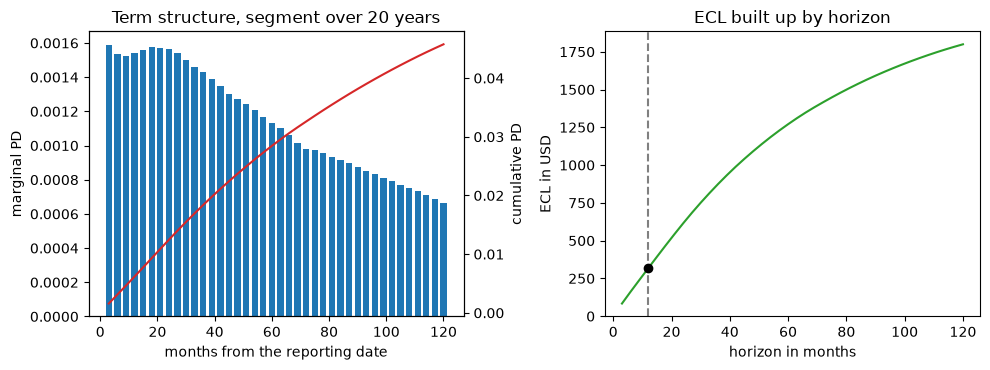

In [11]:
# Draw the term structure of the segment and the ECL built up by horizon
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.bar(months, ts.marginal, width=2.2, color="tab:blue", label="marginal PD")
left.set_xlabel("months from the reporting date")
left.set_ylabel("marginal PD")
twin = left.twinx()
twin.plot(months, ts.cumulative, color="tab:red", label="cumulative PD")
twin.set_ylabel("cumulative PD")
left.set_title("Term structure, segment over 20 years")

running = np.cumsum(contributions)
right.plot(months, running, color="tab:green")
right.axvline(12, color="grey", linestyle="--")
right.scatter([12], [ecl_12], color="black", zorder=3)
right.set_xlabel("horizon in months")
right.set_ylabel("ECL in USD")
right.set_title("ECL built up by horizon")
fig.tight_layout()
plt.show()

## Results

- **The identities close.** On the 40 quarters of the long-loan segment the survival, the marginal and the cumulative PD satisfy the three identities, and the engine reproduces the committed marginal and cumulative PD within 1e-9. The artifact was baked by engine 0.5.0 and read here with 0.8.1; the term-structure functions give the same arrays, which is what the check says and nothing more.
- **One hazard, three doors.** `from_marginal` and `from_cumulative` return the hazard of step 1. A cumulative PD that falls is refused with a `ValueError` whose message names the rule, which is how an input error becomes a message and not a wrong ECL.
- **The first year is a small part of a long loan.** The PD of the first 12 months is 0.0062, the PD of months 12 to 120 given survival to month 12 is 0.0398, and the two compose the whole-life PD of 0.0458. This is why a loan that moves from Stage 1 to Stage 2 changes its measurement so much.
- **Prepayment matters, and Contraste's lifetime PD does not carry it.** With an illustrative prepayment hazard of 1% a quarter the cumulative default incidence falls from 0.0458 to 0.0390, and 36% of the loans leave the book by one of the two exits. C06 treats prepayment as censoring (finding `F-PREPAYMENT`), so on this point its lifetime ECL is on the cautious side.
- **The ECL is a sum you can read.** For the lesson account (100,000 USD, 8% a year) the 12-month ECL is 317.09 USD (0.32% of the exposure) and the lifetime ECL is 1,799.23 USD (1.80%), 5.67 times larger. The engine and the sum written by hand agree.
- **Convention and rate are not equal choices.** The end-of-period convention lowers the lifetime ECL by 0.96%; a risk-free rate of 2% raises it by 24.7%, which is why IFRS 9 fixes the rate at the EIR.
- **The horizon effect depends on the term.** The ratio of the lifetime to the 12-month ECL is 2.21 for the loans up to 5 years, 3.79 for 5 to 10 years, 5.05 for 10 to 20 years and 5.67 above 20 years. The two shortest segments carry a loss given default of 1.0, the pipeline's charge-off severity proxy, which has an upward bias (finding `F-LGD-PROXY`).

What this notebook does not show: the exposure and the rate are inputs of the lesson, not data of the file, and the pipeline amortises the balance (finding `F-EAD-MODEL`) where the lesson keeps it constant. The staging that decides which of the two ECLs a loan carries is notebook 02; the weighting of the three scenarios is notebook 03.

## Summary

- The survival, the marginal and the cumulative PD are one object seen three ways; the engine builds it from a hazard, a marginal PD or a cumulative PD and refuses inputs that are not valid.
- The ECL of an account is the sum over periods of the marginal PD, the loss given default, the exposure and the discount factor. The 12-month ECL and the lifetime ECL are the same sum cut at two horizons.
- Discounting is at the original EIR, mid-period by Contraste's documented setting; the alternative convention and, above all, a risk-free rate change the figure without changing the risk.
- A competing exit such as prepayment lowers the default incidence and is not the same as the complement of the survival; C06 records its choice (censoring) as a finding.
- A recomputation is compared with the committed artifact only after naming the engine version that baked it.

**What to try next.** Change `PREPAY_HAZARD` to 0 and then to 0.03 and watch the default incidence; change `SEGMENT` to `term-le-60`. Then continue with notebook 02, which decides which of the two ECLs each loan carries.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf